In [105]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
from matplotlib.lines import Line2D

In [49]:
# binary penetration parameter:
betas = [0.5, 0.6, 0.7, 0.8]

# semimajor axes (in units of R_col=2*R_star):
alphas = np.arange(3, 16)

In [50]:
# load file, example:
beta, alpha = 0.5, 3
file = f'results_verifyFig5_beta{beta}_alpha{alpha}.csv'
df = pd.read_csv(file)
df.columns

Index(['CSV', 'M_smbh', 'm1', 'type1', 'R1', 'm2', 'type2', 'R2', 'a_bin',
       'e_bin', 'v_inf', 'beta', 'incl', 'Omega', 'omega', 'nu', 'rtol',
       'outcome', 'exit_mode', 'a_new_AU', 'e_new', 'v_esc_kms', 'beta_actual',
       'rp_body1_Rg', 'rp_body2_Rg', 'rp_inner_AU', 'R1_used_Rsun',
       'R2_used_Rsun', 'Rsmbh_Rsun', 't_sim_yr', 'wall_s'],
      dtype='object')

In [48]:
# example calculation:
df["outcome"][df["outcome"].str.contains("COLLISION")].size / df["outcome"].size

0.2

In [46]:
# outcome keys:
df["outcome"].unique()

array(['FLYBY', 'BOUND_TRIPLE', 'COLLISION:star1+star2', 'EXCHANGE_star1'],
      dtype=object)

In [45]:
# define data structure:
statistics = pd.DataFrame(index=alphas, columns=betas)

In [53]:
# auxiliary function:
def binomial_error(f, N):
    """
    f: probability for successful trial.
    N: number of trials.
    """
    return np.sqrt(f*(1-f)/N)

In [144]:
results = []

for beta in tqdm(betas):
    for alpha in alphas:
        file = f'results_verifyFig5_beta{beta}_alpha{alpha}.csv'
        df = pd.read_csv(file)

        outcomes = df["outcome"]
        N_sims = outcomes.size

        # Compute counts/fractions
        f_COLLISION = outcomes.str.contains("COLLISION").sum() / N_sims
        f_FLYBY = outcomes.str.contains("FLYBY").sum() / N_sims
        f_BOUND_TRIPLE = outcomes.str.contains("BOUND_TRIPLE").sum() / N_sims
        f_EXCHANGE = outcomes.str.contains("EXCHANGE").sum() / N_sims

        # Error estimates
        df_COLLISION = binomial_error(f_COLLISION, N_sims)
        df_FLYBY = binomial_error(f_FLYBY, N_sims)
        df_BOUND_TRIPLE = binomial_error(f_BOUND_TRIPLE, N_sims)
        df_EXCHANGE = binomial_error(f_EXCHANGE, N_sims)

        # Store summary values (use .mean() or similar scalar aggregates for array columns)
        results.append({
            'alpha': alpha,
            'beta': beta,
            'f_COLLISION': f_COLLISION,
            'df_COLLISION': df_COLLISION,
            'f_FLYBY': f_FLYBY,
            'df_FLYBY': df_FLYBY,
            'f_BOUND_TRIPLE': f_BOUND_TRIPLE,
            'df_BOUND_TRIPLE': df_BOUND_TRIPLE,
            'f_EXCHANGE': f_EXCHANGE,
            'df_EXCHANGE': df_EXCHANGE,
            'v_esc_kms': df["v_esc_kms"],
            'a_new': df["a_new_AU"],
            'e_new': df["e_new"]
        })

# Create clean DataFrame at the end
statistics = pd.DataFrame(results).set_index(['alpha', 'beta'])

100%|███████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00, 30.88it/s]


# Collision probability:

Text(0, 0.5, 'Fraction of collisions')

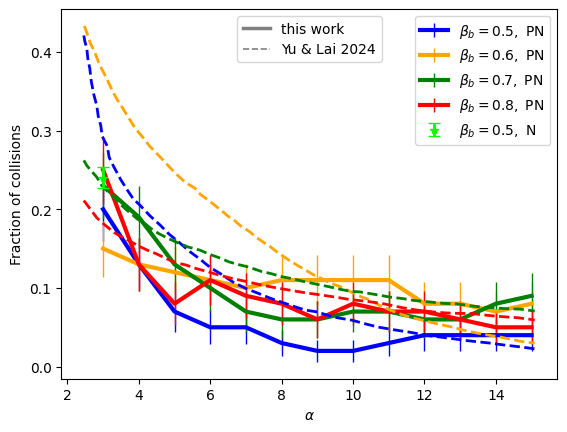

In [219]:
fmt = '-'
c1, c2, c3, c4 = 'blue', 'orange', 'green', 'red'
lw = 3
capsize = 0
elinewidth = 1
capthick = 0.8

plt.errorbar(alphas, [statistics.loc[alpha, 0.5]['f_COLLISION'] for alpha in alphas], fmt=fmt, color=c1, label=r'$\beta_b=0.5,$ PN', lw=lw,
             yerr=[statistics.loc[alpha, 0.5]['df_COLLISION'] for alpha in alphas], capsize=capsize, elinewidth=elinewidth, capthick=capthick, zorder=1)

plt.errorbar(alphas, [statistics.loc[alpha, 0.6]['f_COLLISION'] for alpha in alphas], fmt=fmt, color=c2, label=r'$\beta_b=0.6,$ PN', lw=lw,
             yerr=[statistics.loc[alpha, 0.6]['df_COLLISION'] for alpha in alphas], capsize=capsize, elinewidth=elinewidth, capthick=capthick, zorder=1)

plt.errorbar(alphas, [statistics.loc[alpha, 0.7]['f_COLLISION'] for alpha in alphas], fmt=fmt, color=c3, label=r'$\beta_b=0.7,$ PN', lw=lw,
             yerr=[statistics.loc[alpha, 0.7]['df_COLLISION'] for alpha in alphas], capsize=capsize, elinewidth=elinewidth, capthick=capthick, zorder=1)

plt.errorbar(alphas, [statistics.loc[alpha, 0.8]['f_COLLISION'] for alpha in alphas], fmt=fmt, color=c4, label=r'$\beta_b=0.8,$ PN', lw=lw,
             yerr=[statistics.loc[alpha, 0.8]['df_COLLISION'] for alpha in alphas], capsize=capsize, elinewidth=elinewidth, capthick=capthick, zorder=1)

lw = 2
ls = '--'

a, f = np.loadtxt('YuLaiFig5_beta05.txt', unpack=True)
plt.plot(a, f, color=c1, lw=lw, ls=ls)

a, f = np.loadtxt('YuLaiFig5_beta06.txt', unpack=True)
plt.plot(a, f, color=c2, lw=lw, ls=ls)

a, f = np.loadtxt('YuLaiFig5_beta07.txt', unpack=True)
plt.plot(a, f, color=c3, lw=lw, ls=ls)

a, f = np.loadtxt('YuLaiFig5_beta08.txt', unpack=True)
plt.plot(a, f, color=c4, lw=lw, ls=ls)

# Get the current axes
ax = plt.gca()

# Create dummy lines for the line style legend
style_handles = [
    Line2D([0], [0], color='gray', linewidth=2.5, linestyle='-', label='this work'),
    Line2D([0], [0], color='gray', linewidth=1.2, linestyle='--', label='Yu & Lai 2024')
]

file = f'results_newt_b0.5_a3_N1000.csv'
df = pd.read_csv(file)
outcomes = df["outcome"]
N = outcomes.size
f = outcomes.str.contains("COLLISION").sum() / N
df = binomial_error(f, N)
plt.errorbar(3, f, fmt='*', color='lime', yerr=df, capsize=4, lw=2, zorder=2, label=r'$\beta_b=0.5,$ N')

# Create the second legend
leg2 = ax.legend(handles=style_handles, loc='upper center')

# IMPORTANT: Re-add the second legend as an artist so Matplotlib doesn't remove the first one
ax.add_artist(leg2)

plt.legend(loc='upper right')

plt.xlabel(r'$\alpha$')
plt.ylabel('Fraction of collisions')

Text(0, 0.5, 'Fraction of collisions')

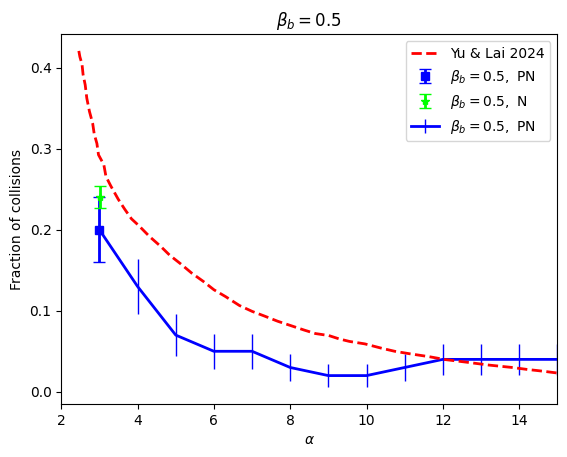

In [240]:
# zoom in:

file = f'results_verifyFig5_beta0.5_alpha3.csv'
df = pd.read_csv(file)
outcomes = df["outcome"]
N = outcomes.size
f = outcomes.str.contains("COLLISION").sum() / N
df = binomial_error(f, N)
plt.errorbar(2.99, f, fmt='s', color='b', yerr=df, capsize=4, lw=2, zorder=2, label=r'$\beta_b=0.5,$ PN')

file = f'results_newt_b0.5_a3_N1000.csv'
df = pd.read_csv(file)
outcomes = df["outcome"]
N = outcomes.size
f = outcomes.str.contains("COLLISION").sum() / N
df = binomial_error(f, N)
plt.errorbar(3.01, f, fmt='*', color='lime', yerr=df, capsize=4, lw=2, zorder=2, label=r'$\beta_b=0.5,$ N')

a, f = np.loadtxt('YuLaiFig5_beta05.txt', unpack=True)
plt.plot(a, f, color='r', lw=2, ls=ls, label='Yu & Lai 2024')

plt.errorbar(alphas, [statistics.loc[alpha, 0.5]['f_COLLISION'] for alpha in alphas], fmt=fmt, color='b', label=r'$\beta_b=0.5,$ PN', lw=lw,
             yerr=[statistics.loc[alpha, 0.5]['df_COLLISION'] for alpha in alphas], capsize=capsize, elinewidth=elinewidth, capthick=capthick, zorder=1)

plt.xlim(2, 15)

plt.legend()
plt.title(r'$\beta_b=0.5$')

plt.xlabel(r'$\alpha$')
plt.ylabel('Fraction of collisions')

# Branching ratios:

Text(0.5, 1.0, '$\\beta_b=0.5$')

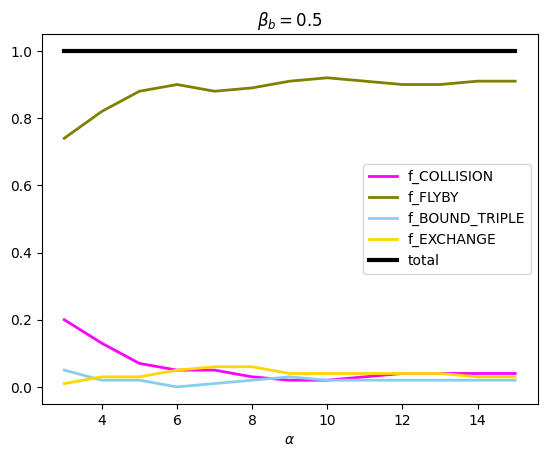

In [142]:
beta = 0.5
outcomes = ['f_COLLISION', 'f_FLYBY', 'f_BOUND_TRIPLE', 'f_EXCHANGE']
colors = ['magenta', 'olive', 'skyblue', 'gold']

for i in range(len(outcomes)):
    plt.plot(alphas, [statistics.loc[alpha, beta][outcomes[i]] for alpha in alphas], color=colors[i], lw=2, label=outcomes[i])

plt.plot(alphas, [np.sum([statistics.loc[alpha, beta][outcome] for outcome in outcomes]) for alpha in alphas], color='k', lw=3, label='total')

plt.legend()
plt.xlabel(r'$\alpha$')
plt.title(rf'$\beta_b={beta}$')

Text(0.5, 1.0, '$\\beta_b=0.6$')

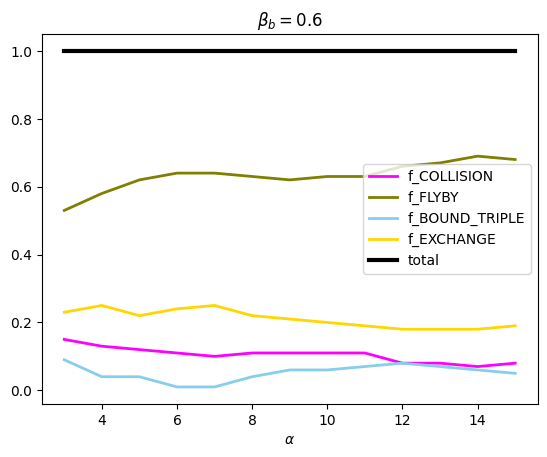

In [139]:
beta = 0.6
outcomes = ['f_COLLISION', 'f_FLYBY', 'f_BOUND_TRIPLE', 'f_EXCHANGE']
colors = ['magenta', 'olive', 'skyblue', 'gold']

for i in range(len(outcomes)):
    plt.plot(alphas, [statistics.loc[alpha, beta][outcomes[i]] for alpha in alphas], color=colors[i], lw=2, label=outcomes[i])

plt.plot(alphas, [np.sum([statistics.loc[alpha, beta][outcome] for outcome in outcomes]) for alpha in alphas], color='k', lw=3, label='total')

plt.legend()
plt.xlabel(r'$\alpha$')
plt.title(rf'$\beta_b={beta}$')

Text(0.5, 1.0, '$\\beta_b=0.7$')

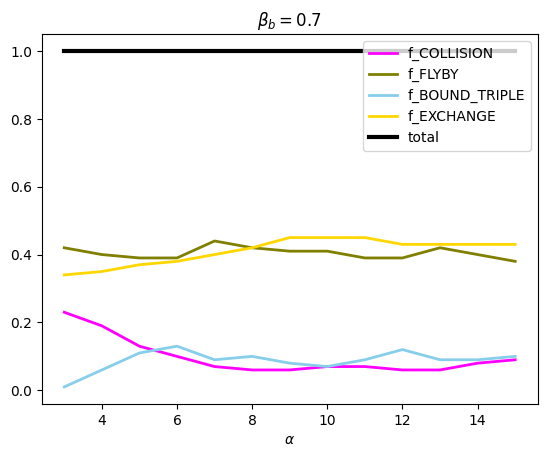

In [140]:
beta = 0.7
outcomes = ['f_COLLISION', 'f_FLYBY', 'f_BOUND_TRIPLE', 'f_EXCHANGE']
colors = ['magenta', 'olive', 'skyblue', 'gold']

for i in range(len(outcomes)):
    plt.plot(alphas, [statistics.loc[alpha, beta][outcomes[i]] for alpha in alphas], color=colors[i], lw=2, label=outcomes[i])

plt.plot(alphas, [np.sum([statistics.loc[alpha, beta][outcome] for outcome in outcomes]) for alpha in alphas], color='k', lw=3, label='total')

plt.legend()
plt.xlabel(r'$\alpha$')
plt.title(rf'$\beta_b={beta}$')

Text(0.5, 1.0, '$\\beta_b=0.8$')

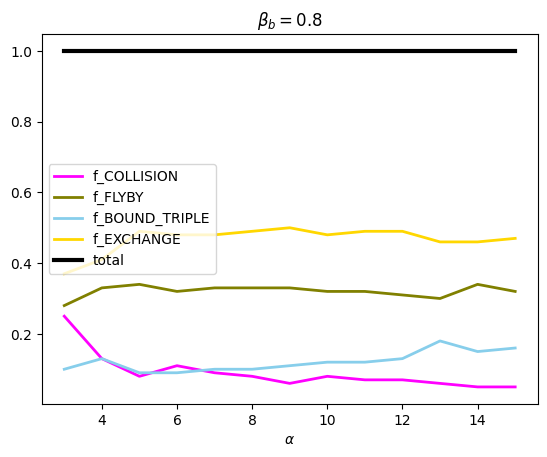

In [141]:
beta = 0.8
outcomes = ['f_COLLISION', 'f_FLYBY', 'f_BOUND_TRIPLE', 'f_EXCHANGE']
colors = ['magenta', 'olive', 'skyblue', 'gold']

for i in range(len(outcomes)):
    plt.plot(alphas, [statistics.loc[alpha, beta][outcomes[i]] for alpha in alphas], color=colors[i], lw=2, label=outcomes[i])

plt.plot(alphas, [np.sum([statistics.loc[alpha, beta][outcome] for outcome in outcomes]) for alpha in alphas], color='k', lw=3, label='total')

plt.legend()
plt.xlabel(r'$\alpha$')
plt.title(rf'$\beta_b={beta}$')

# Fraction of breakups:

Text(0, 0.5, 'Fraction of breakups')

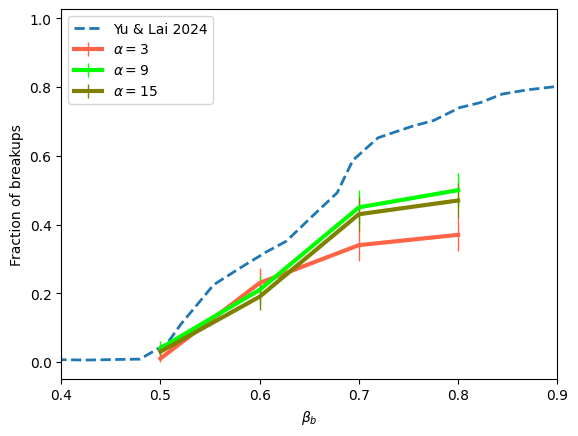

In [181]:
fmt = '-'
c1, c2, c3 = 'tomato', 'lime', 'olive'
lw = 3
capsize = 0
elinewidth = 1
capthick = 0.8

a = 3
plt.errorbar(betas, [statistics.loc[a, beta]['f_EXCHANGE'] for beta in betas], fmt=fmt, color=c1, label=r'$\alpha=3$', lw=lw,
             yerr=[statistics.loc[a, beta]['df_EXCHANGE'] for beta in betas], capsize=capsize, elinewidth=elinewidth, capthick=capthick)

a = 9
plt.errorbar(betas, [statistics.loc[a, beta]['f_EXCHANGE'] for beta in betas], fmt=fmt, color=c2, label=r'$\alpha=9$', lw=lw,
             yerr=[statistics.loc[a, beta]['df_EXCHANGE'] for beta in betas], capsize=capsize, elinewidth=elinewidth, capthick=capthick)


a = 15
plt.errorbar(betas, [statistics.loc[a, beta]['f_EXCHANGE'] for beta in betas], fmt=fmt, color=c3, label=r'$\alpha=15$', lw=lw,
             yerr=[statistics.loc[a, beta]['df_EXCHANGE'] for beta in betas], capsize=capsize, elinewidth=elinewidth, capthick=capthick)

b, f = np.loadtxt('YuLaiFig1_eb0.txt', unpack=True)
plt.plot(b, f, ls='--', label='Yu & Lai 2024', lw=2)
plt.xlim(0.4, 0.9)

plt.legend()
plt.xlabel(r'$\beta_b$')
plt.ylabel('Fraction of breakups')

# Escaper velocity:
---

#### Theory:

#### Tidal force on reduced mass of binary at radius $r$: $F_{\rm tidal}\approx {4GM_{\rm SMBH}\mu_b a_b\over r^3}$

#### Work done by SMBH: $\Delta E_b = \int_{r_p}^\infty F_{\rm tidal} dr$

#### Thus, $\Delta E_b\approx {2GM_{\rm SMBH}\mu_b a_b \over r_p^2}$ and is $\gg E_b={Gm_\star^2\over2 a_b}$ and $\mu_b=m_\star/2$

#### The pericenter is $r_p=\beta_b^{-1} a_b \left({M_{\rm SMBH}\over2m_\star}\right)^{1/3}$, therefore $\Delta E_b \approx 2^{2/3}{\beta_b^2\over\alpha}{GM_{\rm SMBH}^{1/3}m_\star^{5/3}\over 2R_\star}$

#### Energy conservation: $\Delta E_b \approx {1\over2}\mu' V_{\rm HVS}^2$ where $\mu'\approx m_\star$

#### It follows, $V_{\rm HVS}\approx 2^{1/3}{\beta_b\over\sqrt2\alpha}\left({M_{\rm SMBH}\over m_\star}\right)^{1/6} V_{\star}$, where $V_\star$ is the escape velocity from the surface of the solar star, $\approx620\,\rm km\,s^{-1}$. Plugging in our numbers: $V_{\rm HVS}\approx 5500\,{\rm km\,s^{-1}}\,{\beta_b\over\sqrt{\alpha}}$

Text(0.5, 0, '$V_{\\rm HVS}$ (km/s)')

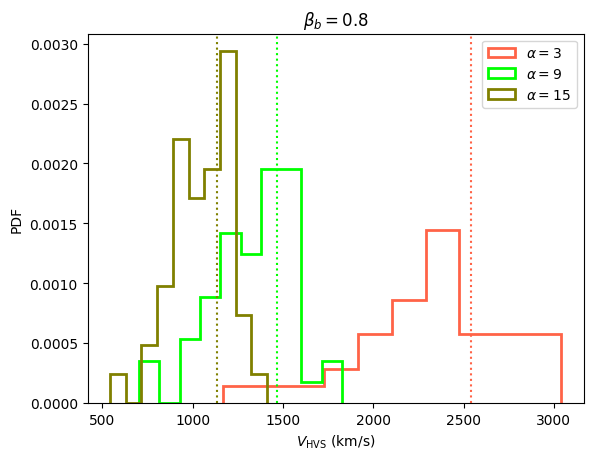

In [224]:
dens = True
histtype = 'step'
lw = 2
c1, c2, c3 = 'tomato', 'lime', 'olive'

plt.hist(statistics.loc[3, 0.8]["v_esc_kms"], density=dens, histtype=histtype, lw=lw, color=c1, label=r'$\alpha=3$')
plt.hist(statistics.loc[9, 0.8]["v_esc_kms"], density=dens, histtype=histtype, lw=lw, color=c2, label=r'$\alpha=9$')
plt.hist(statistics.loc[15, 0.8]["v_esc_kms"], density=dens, histtype=histtype, lw=lw, color=c3, label=r'$\alpha=15$')

plt.axvline(x=5500*0.8/np.sqrt(3), color=c1, ls='dotted')
plt.axvline(x=5500*0.8/np.sqrt(9), color=c2, ls='dotted')
plt.axvline(x=5500*0.8/np.sqrt(15), color=c3, ls='dotted')

plt.title(r'$\beta_b=0.8$')
plt.legend()
plt.ylabel('PDF')
plt.xlabel(r'$V_{\rm HVS}$ (km/s)')

# Relativistic effects cause the discrepancy?
---

#### We see most deviation in the comparison with Yu & Lai (2024) for small values of $\alpha$, i.e., for compact binaries, close to contact. Such binaries have smaller tidal radii, since the latter scales proportionally with semimajor axis, thus the binary approaches closer to the SMBH horizon scale. It becomes interesting whether this difference is attributed to relativistic effects included in our simulations, but ignored by Yu & Lai (2024). 

#### In the simulations with SpaceHub I forgot to turn off PN terms (1 PN, 2 PN, 2.5 PN).

#### The calculation below estimate the importance of relativistic effects:

### ${r_p\over R_g} = {2\alpha\over\beta_b}{R_\star\over R_g} \left({M_{\rm SMBH}\over2m_\star}\right)^{1/3}$ which is $\approx74\alpha/\beta_b$ for the parameters we used, and it is always $>270$; thus GR effects should be negligible.

#### The difference is bigger for $\beta_b=0.5$ where the binary approaches the least to the SMBH. Hence, GR effects are probably not the cause.

In [ ]:
# 1PN: v/c ^ 2 ~ 0.01^2 -> 1e-4